# Regularized linear models and SVMs on omics data

**Practical class – Ridge, Lasso, Elastic Net, and Support Vector Machines**

In omics studies we usually have **many more variables than samples** ($p \gg n$): thousands of genes measured in a few dozen samples. Ordinary least squares and unpenalized logistic regression break down in this setting, and regularization becomes essential — both to obtain models that generalize and to select a small set of candidate genes.

| Part | Task | Dataset | $n$ | $p$ | Response |
|---|---|---|---|---|---|
| A | Linear regression | *Bacillus subtilis* riboflavin production (Bühlmann *et al.*, 2014; R package `hdi`) | 71 | 4088 genes | log production rate (continuous) |
| B | Logistic regression | Prostate cancer (Singh *et al.*, 2002; R package `spls`) | 102 | 6033 genes | tumour (1) vs normal (0) |
| C | SVMs | same prostate data | 102 | 6033 genes | tumour (1) vs normal (0) |

**Objectives**

1. See why OLS / unpenalized logistic regression fail when $p \gg n$.
2. Use Ridge ($L_2$), Lasso ($L_1$) and Elastic Net, and choose the penalty strength by cross-validation.
3. Avoid **data leakage** and estimate performance honestly with **nested cross-validation**.
4. Fit linear and RBF **SVMs** to the same classification problem, tune `C` and `gamma`, and compare them with penalized logistic regression.

Objective functions (standardized predictors):

$$\text{Ridge: } \min_\beta \; \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \tfrac{\alpha}{2}\lVert\beta\rVert_2^2 \qquad
\text{Lasso: } \min_\beta \; \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \alpha\lVert\beta\rVert_1$$

$$\text{Elastic Net: } \min_\beta \; \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \alpha\Big(\rho\lVert\beta\rVert_1 + \tfrac{1-\rho}{2}\lVert\beta\rVert_2^2\Big)$$

In scikit-learn $\alpha$ is `alpha` and $\rho$ is `l1_ratio`. For **logistic regression and SVMs** the penalty strength is given as `C` $\approx 1/\alpha$: **larger `C` = weaker penalty**.

> **Exercises** are marked `TODO` (5 in total). Everything else can be run as it is.
> Suggested pacing: Part A ~20 min · Part B ~15 min · Part C ~15 min.

In [1]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  RidgeCV, LassoCV, ElasticNetCV, LogisticRegression)
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (r2_score, roc_auc_score, roc_curve, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 100
RNG = 42
print("scikit-learn", sklearn.__version__)

ModuleNotFoundError: No module named 'sklearn'

### Loading the data

The two datasets are compressed CSV files in the `data/` folder next to this notebook. If they are missing, the cell below rebuilds them from the GitHub mirror of CRAN (requires `pip install rdata`).

In [ ]:
DATA = "data"

def download_datasets(folder=DATA):
    import urllib.request, rdata
    os.makedirs(folder, exist_ok=True)
    base = "https://raw.githubusercontent.com/cran"
    urllib.request.urlretrieve(f"{base}/hdi/master/data/riboflavin.RData", "riboflavin.RData")
    cm = dict(rdata.conversion.DEFAULT_CLASS_MAP)
    cm["data.frame"] = lambda obj, attrs: obj
    cm["AsIs"] = lambda obj, attrs: obj
    rb = rdata.conversion.convert(rdata.parser.parse_file("riboflavin.RData"), cm)["riboflavin"]
    xm = rb["x"]
    X = pd.DataFrame(np.asarray(xm), index=np.asarray(xm.coords[xm.dims[0]]).astype(str),
                     columns=np.asarray(xm.coords[xm.dims[1]]).astype(str))
    X.insert(0, "q_RIBFLV", np.asarray(rb["y"]))
    X.to_csv(f"{folder}/riboflavin.csv.gz", compression="gzip")
    urllib.request.urlretrieve(f"{base}/spls/master/data/prostate.RData", "prostate.RData")
    pr = rdata.conversion.convert(rdata.parser.parse_file("prostate.RData"))["prostate"]
    P = pd.DataFrame(pr["x"], columns=[f"g{i+1}" for i in range(pr["x"].shape[1])])
    P.insert(0, "tumor", np.asarray(pr["y"]).astype(int))
    P.to_csv(f"{folder}/prostate_singh2002.csv.gz", compression="gzip", index=False)

if not (os.path.exists(f"{DATA}/riboflavin.csv.gz") and os.path.exists(f"{DATA}/prostate_singh2002.csv.gz")):
    download_datasets()

ribo = pd.read_csv(f"{DATA}/riboflavin.csv.gz", index_col=0)
prost = pd.read_csv(f"{DATA}/prostate_singh2002.csv.gz")
print("riboflavin:", ribo.shape, "| prostate:", prost.shape)

riboflavin: (71, 4089) | prostate: (102, 6034)


---
# Part A – Linear regression: riboflavin production from gene expression

`q_RIBFLV` is the log riboflavin (vitamin B2) production rate of 71 *B. subtilis* fermentation samples; the predictors are log2 expression levels of 4088 genes. We want to predict production and to identify associated genes — relevant for metabolic engineering of production strains.

n = 71 samples, p = 4088 genes  (p/n = 58)


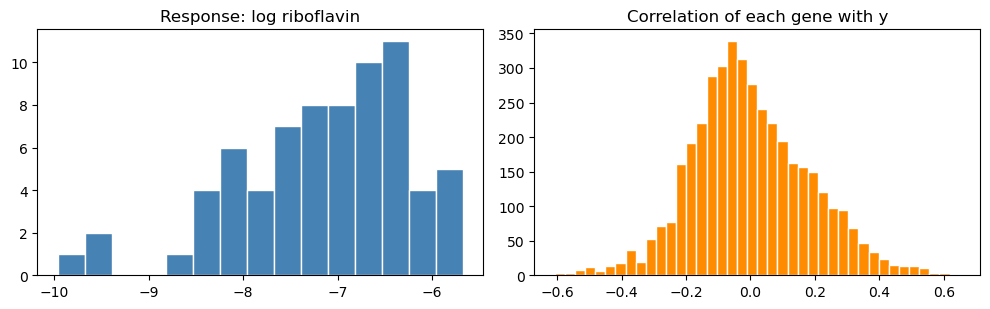

,gene,corr_with_y
0,XHLA_at,0.649
1,XHLB_at,0.628
2,YXLD_at,-0.608
3,YCKE_at,0.606
4,XKDF_at,0.604


In [3]:
y_r = ribo["q_RIBFLV"].values
X_r = ribo.drop(columns="q_RIBFLV")
genes_r = X_r.columns.to_numpy()
X_r = X_r.values
n, p = X_r.shape
print(f"n = {n} samples, p = {p} genes  (p/n = {p/n:.0f})")

corr = np.array([np.corrcoef(X_r[:, j], y_r)[0, 1] for j in range(p)])
top = np.argsort(-np.abs(corr))[:10]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_r, bins=15, color="steelblue", edgecolor="white"); ax[0].set_title("Response: log riboflavin")
ax[1].hist(corr, bins=40, color="darkorange", edgecolor="white"); ax[1].set_title("Correlation of each gene with y")
plt.tight_layout(); plt.show()
pd.DataFrame({"gene": genes_r[top], "corr_with_y": corr[top].round(3)}).head(5)

## A.1 OLS when $p \gg n$, and the danger of data leakage

With more unknowns than equations $X^\top X$ is singular: there are infinitely many exact solutions and `LinearRegression` returns the minimum-norm one. A common shortcut is to keep the $k$ genes most correlated with $y$ and fit OLS on those — but **where** that selection happens changes everything.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=RNG)
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_r, y_r)
print(f"Training R^2 (OLS, all genes): {r2_score(y_r, ols.predict(X_r)):.3f}")
print(f"5-fold CV R^2 (OLS, all genes): {cross_val_score(ols, X_r, y_r, cv=cv, scoring='r2').mean():.3f}")

k = 10
# WRONG: genes chosen using ALL samples, then only the OLS fit is cross-validated
X_top = SelectKBest(f_regression, k=k).fit_transform(X_r, y_r)
r2_leak = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X_top, y_r, cv=cv, scoring="r2")
# RIGHT: selection is a step of the pipeline, redone inside each training fold
pipe_ok = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=k), LinearRegression())
r2_ok = cross_val_score(pipe_ok, X_r, y_r, cv=cv, scoring="r2")
print(f"\nTop-{k} genes, selection OUTSIDE CV (leakage): R^2 = {r2_leak.mean():.3f}")
print(f"Top-{k} genes, selection INSIDE CV (correct):  R^2 = {r2_ok.mean():.3f}")

Training R^2 (OLS, all genes): 1.000
5-fold CV R^2 (OLS, all genes): 0.552

Top-10 genes, selection OUTSIDE CV (leakage): R^2 = 0.429
Top-10 genes, selection INSIDE CV (correct):  R^2 = 0.311


**Question A.1.** (a) Why is the training $R^2$ exactly 1? (b) Explain the gap between the two top-10 estimates. Which one would you report in a paper?

*Your answer:*



## A.2 Ridge ($L_2$): shrink everything

Ridge shrinks all coefficients towards zero but never exactly to zero. Predictors must be **standardized**, otherwise the penalty depends on the measurement scale of each gene.

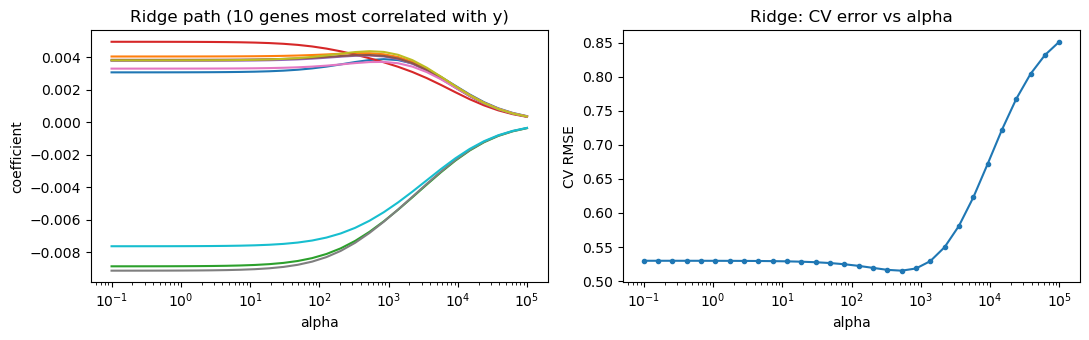

best alpha = 329.0; non-zero coefficients: 4088 of 4088


In [5]:
alphas_ridge = np.logspace(-1, 5, 30)
Xs = StandardScaler().fit_transform(X_r)
coefs = np.array([Ridge(alpha=a).fit(Xs, y_r).coef_ for a in alphas_ridge])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(alphas_ridge, coefs[:, top], lw=1.5)
ax[0].set_xscale("log"); ax[0].set_xlabel("alpha"); ax[0].set_ylabel("coefficient")
ax[0].set_title("Ridge path (10 genes most correlated with y)")
cv_rmse = [-cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), X_r, y_r, cv=cv,
                            scoring="neg_root_mean_squared_error").mean() for a in alphas_ridge]
ax[1].plot(alphas_ridge, cv_rmse, "o-", ms=3); ax[1].set_xscale("log")
ax[1].set_xlabel("alpha"); ax[1].set_ylabel("CV RMSE"); ax[1].set_title("Ridge: CV error vs alpha")
plt.tight_layout(); plt.show()

ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_ridge)).fit(X_r, y_r)
print(f"best alpha = {ridge_cv[-1].alpha_:.1f}; non-zero coefficients: {np.sum(ridge_cv[-1].coef_ != 0)} of {p}")

## A.3 Lasso ($L_1$): shrinkage **and** selection

**TODO 1.** Choose `alpha` by 10-fold CV, apply the **one-standard-error rule**, and list the selected genes.

The 1-SE rule keeps the *largest* `alpha` (simplest model) whose mean CV error is within one standard error of the minimum.

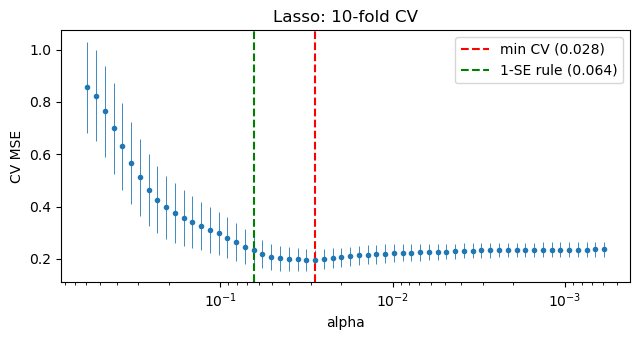

alpha_min = 0.0283: 40 genes selected
alpha_1se = 0.0642: 32 genes selected


,gene,coef (1-SE),coef (min CV)
0,YOAB_at,-0.211,-0.230
1,YXLD_at,-0.207,-0.235
2,ARGF_at,-0.155,-0.193
3,XHLB_at,0.150,0.121
4,YEBC_at,-0.092,-0.115
5,YXLE_at,-0.085,-0.086
6,YDDK_at,-0.078,-0.062
7,LYSC_at,-0.064,-0.079
8,DNAJ_at,-0.053,-0.032
9,YCKE_at,0.046,0.010


In [7]:
# TODO 1a: build a grid of alphas. A convenient upper end is
#           alpha_max = max_j |x_j . (y - mean(y))| / n   on the STANDARDIZED matrix Xs
#           (the smallest alpha for which every coefficient is zero); go down to alpha_max * 1e-3.

alpha_max = np.max(np.abs(Xs.T @ (y_r - y_r.mean()))) / n   # max alpha giving an all-zero model
ALPHAS_L = np.logspace(np.log10(alpha_max), np.log10(alpha_max * 1e-3), 60)

# TODO 1b: fit LassoCV (10-fold) inside a pipeline with StandardScaler, on that grid.

lasso_cv = make_pipeline(StandardScaler(),
                         LassoCV(cv=KFold(10, shuffle=True, random_state=RNG), alphas=ALPHAS_L,
                                 max_iter=50000, random_state=RNG)).fit(X_r, y_r)

# TODO 1c: from `.mse_path_`, plot the mean CV MSE +/- 1 standard error against alpha, and mark
#          alpha_min and alpha_1se (largest alpha whose mean CV error is within 1 SE of the minimum).
#          Store alpha_1se in a variable `alpha_1se` - it is reused below.

m = lasso_cv[-1]
mse_mean = m.mse_path_.mean(axis=1)
mse_se = m.mse_path_.std(axis=1) / np.sqrt(m.mse_path_.shape[1])
i_min = np.argmin(mse_mean)
alpha_1se = m.alphas_[np.where(mse_mean <= mse_mean[i_min] + mse_se[i_min])[0].min()]

# TODO 1d: how many genes does each rule select? List them with their coefficients.

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.errorbar(m.alphas_, mse_mean, yerr=mse_se, fmt="o", ms=3, elinewidth=0.6)
ax.axvline(m.alpha_, color="r", ls="--", label=f"min CV ({m.alpha_:.3f})")
ax.axvline(alpha_1se, color="g", ls="--", label=f"1-SE rule ({alpha_1se:.3f})")
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("alpha"); ax.set_ylabel("CV MSE")
ax.legend(); ax.set_title("Lasso: 10-fold CV"); plt.tight_layout(); plt.show()

lasso_min = m.coef_
lasso_1se = Lasso(alpha=alpha_1se, max_iter=50000).fit(Xs, y_r).coef_
print(f"alpha_min = {m.alpha_:.4f}: {np.sum(lasso_min != 0)} genes selected")
print(f"alpha_1se = {alpha_1se:.4f}: {np.sum(lasso_1se != 0)} genes selected")
sel = np.argsort(-np.abs(lasso_1se))[:np.sum(lasso_1se != 0)]
pd.DataFrame({"gene": genes_r[sel], "coef (1-SE)": lasso_1se[sel].round(3),
              "coef (min CV)": lasso_min[sel].round(3)})

**Question A.3.** Compare the number of genes selected by `alpha_min` and by the 1-SE rule. Why is the 1-SE rule often preferred for biomarker discovery? Is there a limit to how many genes the Lasso can select here?

*Your answer:*



## A.4 Elastic Net and an honest comparison

Genes in the same operon or pathway are strongly correlated. The Lasso keeps one of them; the $L_2$ part of the Elastic Net spreads the weight so that correlated genes enter or leave **together** (*grouping effect*).

The CV error used to *choose* `alpha` is optimistically biased as an estimate of the final model's performance. To compare methods fairly we use **nested CV**: the inner loop tunes the hyperparameters, the outer loop estimates performance.

In [8]:
inner = KFold(5, shuffle=True, random_state=1)
outer = KFold(5, shuffle=True, random_state=RNG)
models = {
    "Mean only (baseline)": DummyRegressor(strategy="mean"),
    "OLS, top-10 genes (filter in CV)": make_pipeline(StandardScaler(), SelectKBest(f_regression, k=10), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_ridge)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=inner, alphas=np.logspace(0, -3, 40), max_iter=50000)),
    "Elastic Net": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=inner,
                                                                alphas=np.logspace(1, -3, 40), max_iter=50000)),
}
res = {}
for name, mdl in models.items():
    s = cross_validate(mdl, X_r, y_r, cv=outer, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    res[name] = {"RMSE": -s["test_rmse"].mean(), "R2": s["test_r2"].mean(), "R2 sd": s["test_r2"].std()}
res_r = pd.DataFrame(res).T.round(3)
display(res_r)

# grouping effect: genes strongly correlated with the top Lasso gene
enet = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=0.1, cv=inner,
                                                    alphas=np.logspace(1, -3, 40), max_iter=50000)).fit(X_r, y_r)
b_enet = enet[-1].coef_
g0 = np.argmax(np.abs(lasso_1se))
r_g0 = Xs.T @ Xs[:, g0] / n
grp = np.where(np.abs(r_g0) > 0.9)[0]
print(f"Elastic Net (l1_ratio=0.1): {np.sum(b_enet != 0)} genes selected")
pd.DataFrame({"gene": genes_r[grp], f"corr with {genes_r[g0]}": r_g0[grp].round(2),
              "Lasso coef": lasso_1se[grp].round(3), "ENet coef": b_enet[grp].round(3)})

,RMSE,R2,R2 sd
Mean only (baseline),0.891,-0.063,0.057
"OLS, top-10 genes (filter in CV)",0.694,0.311,0.161
Ridge,0.559,0.536,0.231
Lasso,0.476,0.672,0.100
Elastic Net,0.509,0.604,0.201


Elastic Net (l1_ratio=0.1): 144 genes selected


,gene,corr with YOAB_at,Lasso coef,ENet coef
0,YOAB_at,1.0,-0.211,-0.078


**Question A.4.** What happens to the coefficients of a group of highly correlated genes under Lasso vs Elastic Net? When would you prefer each one?

*Your answer:*



---
# Part B – Logistic regression: classifying prostate tumours

Singh *et al.* (2002) measured ~6000 genes in 52 prostate tumours and 50 normal tissues. We want a classifier and a short list of discriminating genes. (In this version of the data the gene identifiers are not available, so genes are labelled `g1 … g6033`.)

In [9]:
y_p = prost["tumor"].values
X_p = prost.drop(columns="tumor").values
genes_p = prost.columns[1:].to_numpy()
print(X_p.shape, "| class counts:", dict(zip(*np.unique(y_p, return_counts=True))))

cvs = StratifiedKFold(5, shuffle=True, random_state=RNG)

# scikit-learn >= 1.8 sets the penalty type through l1_ratio; older versions use `penalty`
SK_NEW = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)

def logreg(kind="l2", C=1.0, max_iter=5000):
    if kind == "none":
        return LogisticRegression(C=np.inf, max_iter=max_iter) if SK_NEW else LogisticRegression(penalty=None, max_iter=max_iter)
    if kind == "l2":
        return LogisticRegression(C=C, l1_ratio=0.0, max_iter=max_iter) if SK_NEW else LogisticRegression(penalty="l2", C=C, max_iter=max_iter)
    if kind == "l1":
        return (LogisticRegression(C=C, l1_ratio=1.0, solver="liblinear", max_iter=max_iter, random_state=RNG) if SK_NEW
                else LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=max_iter, random_state=RNG))
    raise ValueError(kind)

# standardize -> keep the k genes with largest |t| (computed on the TRAINING fold only) -> penalized logistic
def logpipe(kind, k=1000, **kw):
    return make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), logreg(kind, **kw))

(102, 6033) | class counts: {np.int64(0): np.int64(50), np.int64(1): np.int64(52)}


## B.1 Unpenalized logistic regression and complete separation

With $p \gg n$ the classes can essentially always be separated perfectly by a hyperplane. The maximum-likelihood estimate then **does not exist**: the likelihood keeps increasing as the coefficients grow, and the optimizer stops only when the loss is numerically zero.

In [10]:
Xp_s = StandardScaler().fit_transform(X_p)
for it in [2, 10, 50]:
    m_ = logreg("none", max_iter=it).fit(Xp_s, y_p)
    pr = m_.predict_proba(Xp_s)[:, 1]
    ll = -np.mean(y_p*np.log(pr+1e-300) + (1-y_p)*np.log(1-pr+1e-300))
    print(f"max_iter={it:3d}:  ||beta|| = {np.linalg.norm(m_.coef_):6.2f}   "
          f"train accuracy = {accuracy_score(y_p, pr > 0.5):.2f}   train log-loss = {ll:.2e}")

max_iter=  2:  ||beta|| =   0.05   train accuracy = 0.76   train log-loss = 5.02e-01
max_iter= 10:  ||beta|| =   0.74   train accuracy = 1.00   train log-loss = 3.20e-03
max_iter= 50:  ||beta|| =   1.25   train accuracy = 1.00   train log-loss = 8.84e-05


**Question B.1.** The cross-validated AUC of an unpenalized model on these data is often not bad at all. Why is the model nonetheless unsatisfactory?

*Your answer:*



## B.2 Tuning $L_2$ and $L_1$ logistic regression

**TODO 2.** Tune `C` for both penalties by stratified 5-fold CV maximizing the AUC, using the helper `logpipe(kind)`.

*Note:* `logpipe` first keeps the 1000 genes with the largest t-statistic. The filter is a step **inside** the pipeline, so it is recomputed on every training fold (no leakage, cf. A.1). With more time, try `k="all"`.

l2   best C = 35.1119   CV AUC = 0.950   non-zero genes = 1000
l1   best C = 0.0658   CV AUC = 0.964   non-zero genes = 3


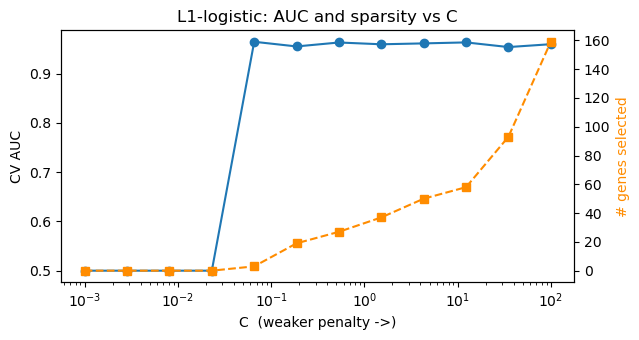

In [11]:
# TODO 2a: with GridSearchCV (cv=cvs, scoring="roc_auc"), tune C over np.logspace(-3, 2, 12) for
#           both the "l2" and the "l1" pipelines given by logpipe(kind).
#           The parameter name inside the pipeline is "logisticregression__C".
#           Store the fitted searches in a dict `tuned` - it is reused below.
#           Report the best C, the CV AUC and the number of non-zero coefficients for each.

Cs = np.logspace(-3, 2, 12)
tuned = {}
for kind in ["l2", "l1"]:
    gs = GridSearchCV(logpipe(kind), {"logisticregression__C": Cs},
                      cv=cvs, scoring="roc_auc", n_jobs=-1).fit(X_p, y_p)
    tuned[kind] = gs
    nzc = np.sum(gs.best_estimator_[-1].coef_ != 0)
    print(f"{kind:3s}  best C = {gs.best_params_['logisticregression__C']:.4f}   "
          f"CV AUC = {gs.best_score_:.3f}   non-zero genes = {nzc}")

# TODO 2b: for the L1 model, plot the CV AUC and the number of selected genes as a function of C
#           (two y-axes). What does the trade-off look like?

nz = [np.sum(logpipe("l1", C=c).fit(X_p, y_p)[-1].coef_ != 0) for c in Cs]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(Cs, tuned["l1"].cv_results_["mean_test_score"], "o-", label="CV AUC")
ax.set_xscale("log"); ax.set_xlabel("C  (weaker penalty ->)"); ax.set_ylabel("CV AUC")
ax2 = ax.twinx(); ax2.plot(Cs, nz, "s--", color="darkorange"); ax2.set_ylabel("# genes selected", color="darkorange")
ax.set_title("L1-logistic: AUC and sparsity vs C"); plt.tight_layout(); plt.show()


## B.3 Nested CV and the selected genes

**TODO 3.** Estimate the AUC honestly with nested CV, and list the genes retained by the $L_1$ model.

In [12]:
# TODO 3a: estimate AUC and accuracy of the L2 and L1 models by NESTED CV:
#           outer StratifiedKFold(5) for evaluation, inner GridSearchCV for tuning C.
#           Hint: cross_val_predict(GridSearchCV(...), X_p, y_p, cv=outer, method="predict_proba")
#           Keep the out-of-fold scores in a dict `nested` - they are reused in Part C.

outer_p = StratifiedKFold(5, shuffle=True, random_state=7)
inner_p = StratifiedKFold(5, shuffle=True, random_state=1)
nested = {}
for kind in ["l2", "l1"]:
    gs = GridSearchCV(logpipe(kind), {"logisticregression__C": Cs}, cv=inner_p, scoring="roc_auc", n_jobs=-1)
    prob = cross_val_predict(gs, X_p, y_p, cv=outer_p, method="predict_proba")[:, 1]
    nested[kind] = {"nested AUC": roc_auc_score(y_p, prob),
                    "nested accuracy": accuracy_score(y_p, prob > 0.5), "scores": prob}
    print(f"{kind:3s}  nested AUC = {nested[kind]['nested AUC']:.3f}   "
          f"accuracy = {nested[kind]['nested accuracy']:.3f}")

# TODO 3b: list the genes kept by the final L1 model (tuned on all the data) with their coefficients
#           and odds ratios per standard deviation. In which class is each gene more expressed?
#           Hint: the surviving genes are genes_p[pipeline.named_steps["selectkbest"].get_support()].

best = tuned["l1"].best_estimator_
b = best[-1].coef_.ravel()
genes_kept = genes_p[best.named_steps["selectkbest"].get_support()]
idx = np.argsort(-np.abs(b))[:np.sum(b != 0)]
pd.DataFrame({"gene": genes_kept[idx], "coef": b[idx].round(3),
              "odds ratio per SD": np.exp(b[idx]).round(2),
              "higher in": np.where(b[idx] > 0, "tumour", "normal")}).head(15)


l2   nested AUC = 0.950   accuracy = 0.931
l1   nested AUC = 0.944   accuracy = 0.941


,gene,coef,odds ratio per SD,higher in
0,g2619,1.003,2.73,tumour
1,g5016,-0.223,0.80,normal
2,g1839,0.126,1.13,tumour


**Question B.3.** (a) Interpret the odds ratio of the top gene. (b) Compare the nested-CV AUC with `best_score_` from B.2 — which one should you report? (c) The $L_1$ model uses a handful of the 6033 genes: is that list "the set of prostate cancer genes"?

*Your answer:*



---
# Part C – Support Vector Machines on the same classification problem

A linear SVM solves

$$\min_{w,b}\;\; C\sum_{i=1}^{n}\max\!\big(0,\,1 - y_i (w^\top x_i + b)\big) \;+\; \tfrac{1}{2}\lVert w\rVert_2^2 ,\qquad y_i \in \{-1,+1\}$$

which is the **hinge loss plus an $L_2$ penalty** — the same ridge-type penalty as in B.2, with a different loss. Two consequences matter here:

* only the examples on or inside the margin (the **support vectors**) have non-zero weight in the solution, whereas in logistic regression *every* sample contributes to the loss;
* `C` plays the role of $1/\alpha$ again: **small `C` = wide margin = strong regularization**.

Replacing the inner products by a **kernel** $K(u,v)$ gives a linear boundary in an implicit feature space; with the Gaussian/RBF kernel $K(u,v) = \exp(-\gamma\lVert u-v\rVert^2)$ the boundary is nonlinear in the original genes, and $\gamma$ controls its flexibility (large $\gamma$ = wiggly = overfitting).

Two practical points, both of which we respect below: SVMs are **distance-based**, so the features *must* be standardized; and an SVM returns a **signed distance** (`decision_function`), not a probability.

## C.1 A 2-gene picture: linear vs RBF boundary

Before fitting anything serious, a visual intuition. We take the two genes with the largest t-statistic and draw the decision boundaries. *This plot is for intuition only*: the two genes were chosen using all the samples, so it is exactly the leakage of A.1 — never do this to estimate performance.

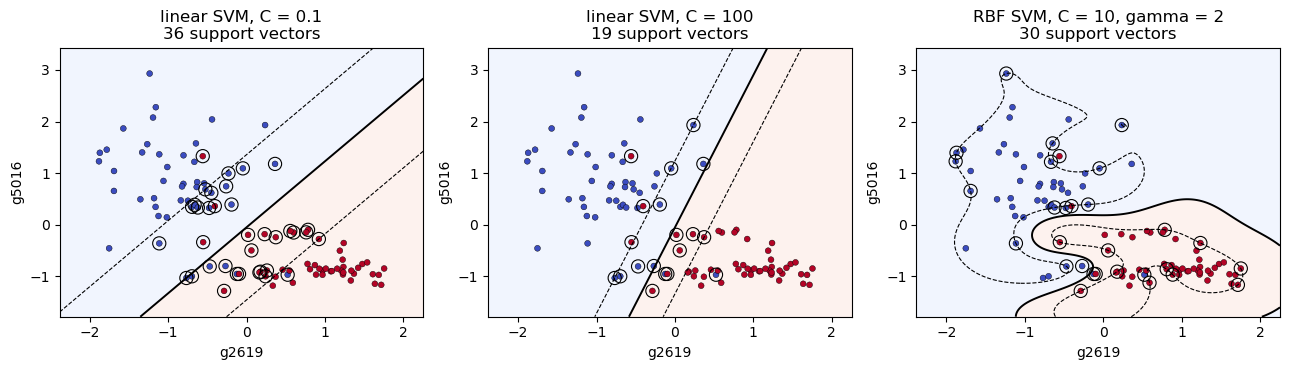

In [13]:
sel2 = SelectKBest(f_classif, k=2).fit(X_p, y_p)
X2 = StandardScaler().fit_transform(sel2.transform(X_p))
names2 = genes_p[sel2.get_support()]

gg = np.meshgrid(np.linspace(X2[:, 0].min()-.5, X2[:, 0].max()+.5, 250),
                 np.linspace(X2[:, 1].min()-.5, X2[:, 1].max()+.5, 250))
grid = np.c_[gg[0].ravel(), gg[1].ravel()]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (ttl, clf) in zip(axes, [
        ("linear SVM, C = 0.1", SVC(kernel="linear", C=0.1)),
        ("linear SVM, C = 100", SVC(kernel="linear", C=100)),
        ("RBF SVM, C = 10, gamma = 2", SVC(kernel="rbf", C=10, gamma=2.0))]):
    clf.fit(X2, y_p)
    Z = clf.decision_function(grid).reshape(gg[0].shape)
    ax.contourf(gg[0], gg[1], Z > 0, alpha=.12, cmap="coolwarm")
    ax.contour(gg[0], gg[1], Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[.8, 1.4, .8])
    ax.scatter(X2[:, 0], X2[:, 1], c=y_p, cmap="coolwarm", s=18, edgecolor="k", linewidth=.3)
    sv = clf.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=90, facecolors="none", edgecolors="k", linewidths=.8)
    ax.set_title(f"{ttl}\n{len(sv)} support vectors"); ax.set_xlabel(names2[0]); ax.set_ylabel(names2[1])
plt.tight_layout(); plt.show()

**Question C.1.** Circled points are the support vectors. Why does the number of support vectors go **down** when `C` goes up? Which of the three models would you expect to generalize best here?

*Your answer:*



## C.2 Tuning an RBF SVM: the `C` × `gamma` grid

**TODO 4.** Tune `C` and `gamma` together by stratified 5-fold CV (AUC) and show the result as a heat map.

As in Part B, the pipeline standardizes and keeps the top 1000 genes inside each training fold.

linear SVM: best C = 0.001   CV AUC = 0.948   support vectors = 58 of 102
RBF SVM:    best C = 1e-05, gamma = 1.0e-02   CV AUC = 0.955


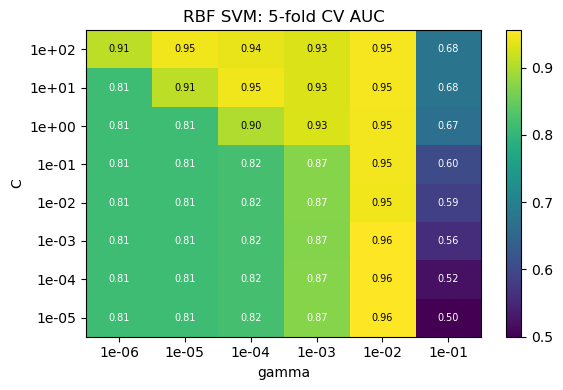

In [14]:
# TODO 4a: write a helper svmpipe(kernel, k=1000, **kw) = StandardScaler -> SelectKBest(f_classif, k)
#           -> SVC(kernel=kernel, **kw), mirroring logpipe from Part B.

def svmpipe(kernel="linear", k=1000, **kw):
    return make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), SVC(kernel=kernel, **kw))

# TODO 4b: tune a LINEAR SVM over C in np.logspace(-3, 3, 7) with GridSearchCV (cv=cvs,
#           scoring="roc_auc"); the parameter name is "svc__C". Report the best C, the CV AUC and
#           the number of support vectors (estimator.n_support_.sum()).

C_grid = np.logspace(-5, 2, 8)
G_grid = np.logspace(-6, -1, 6)

gs_lin = GridSearchCV(svmpipe("linear"), {"svc__C": C_grid},
                      cv=cvs, scoring="roc_auc", n_jobs=-1).fit(X_p, y_p)
print(f"linear SVM: best C = {gs_lin.best_params_['svc__C']:.4g}   CV AUC = {gs_lin.best_score_:.3f}   "
      f"support vectors = {gs_lin.best_estimator_[-1].n_support_.sum()} of {len(y_p)}")

# TODO 4c: tune an RBF SVM over the same C grid and gamma in np.logspace(-6, -1, 6).
#           Store the searches as `gs_lin` and `gs_rbf` - they are reused below.

gs_rbf = GridSearchCV(svmpipe("rbf"), {"svc__C": C_grid, "svc__gamma": G_grid},
                      cv=cvs, scoring="roc_auc", n_jobs=-1).fit(X_p, y_p)
print(f"RBF SVM:    best C = {gs_rbf.best_params_['svc__C']:.4g}, "
      f"gamma = {gs_rbf.best_params_['svc__gamma']:.1e}   CV AUC = {gs_rbf.best_score_:.3f}")

# TODO 4d: reshape gs_rbf.cv_results_["mean_test_score"] into a (len(C_grid), len(G_grid)) matrix
#           and display it as a heat map (plt.imshow), annotating each cell with its AUC.

auc_grid = gs_rbf.cv_results_["mean_test_score"].reshape(len(C_grid), len(G_grid))
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(auc_grid, cmap="viridis", origin="lower", aspect="auto")
ax.set_xticks(range(len(G_grid)), [f"{g:.0e}" for g in G_grid])
ax.set_yticks(range(len(C_grid)), [f"{c:.0e}" for c in C_grid])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("RBF SVM: 5-fold CV AUC")
for i in range(len(C_grid)):
    for j in range(len(G_grid)):
        ax.text(j, i, f"{auc_grid[i, j]:.2f}", ha="center", va="center",
                color="w" if auc_grid[i, j] < auc_grid.max() - .08 else "k", fontsize=7)
fig.colorbar(im); plt.tight_layout(); plt.show()


**Question C.2.** (a) Look at the shape of the good region in the heat map. What does it tell you about tuning `C` and `gamma` separately? (b) The default `gamma="scale"` is $1/(p\,\mathrm{Var}(X))$, i.e. about $10^{-3}$ for 1000 standardized genes. Is that in the good region? (c) The CV AUC of the linear SVM is flat for every `C` above ~$10^{-3}$. Why? (d) Why is the linear SVM so competitive here?

*Your answer:*



## C.3 Honest comparison: logistic regression vs SVMs

**TODO 5.** Put the four classifiers on the same footing with nested CV and draw their ROC curves.

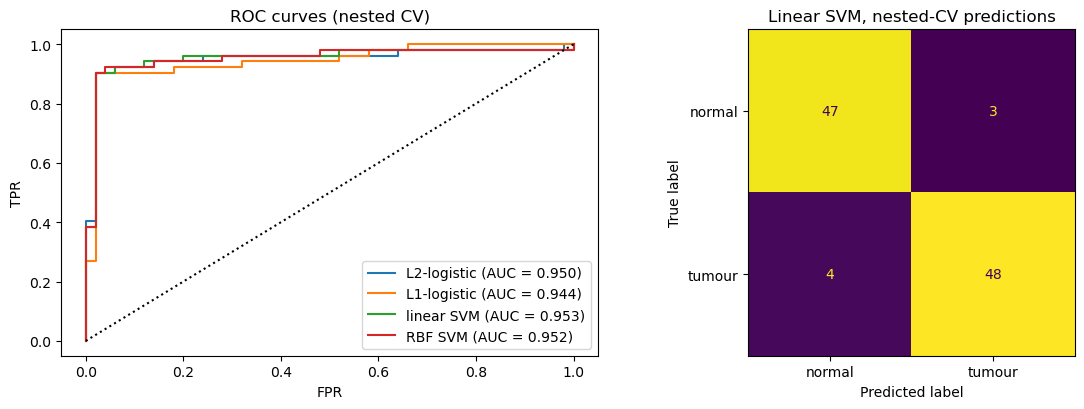

,nested AUC,nested accuracy
model,,
L2-logistic,0.950,0.931
L1-logistic,0.944,0.941
linear SVM,0.953,0.931
RBF SVM,0.952,0.931


In [15]:
# TODO 5a: write a helper that, for a given pipeline and parameter grid, returns the out-of-fold
#           scores obtained with NESTED CV (inner_p for tuning, outer_p for evaluation).
#           For SVMs use method="decision_function" (an SVM has no predict_proba by default);
#           the decision threshold is then 0, not 0.5.

def nested_scores(estimator, grid, name):
    gs = GridSearchCV(estimator, grid, cv=inner_p, scoring="roc_auc", n_jobs=-1)
    s = cross_val_predict(gs, X_p, y_p, cv=outer_p, method="decision_function")
    return {"model": name, "nested AUC": roc_auc_score(y_p, s),
            "nested accuracy": accuracy_score(y_p, s > 0), "scores": s}

# TODO 5b: collect the nested results of the four models - the two logistic ones from `nested`
#           (B.3) and the linear and RBF SVMs - into one table with AUC and accuracy.

rows = [{"model": "L2-logistic", **{k: v for k, v in nested["l2"].items()}},
        {"model": "L1-logistic", **{k: v for k, v in nested["l1"].items()}},
        nested_scores(svmpipe("linear"), {"svc__C": C_grid}, "linear SVM"),
        nested_scores(svmpipe("rbf"), {"svc__C": C_grid, "svc__gamma": G_grid}, "RBF SVM")]



# TODO 5c: plot the four ROC curves on the same axes, and the confusion matrix of the linear SVM.

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for r in rows:
    fpr, tpr, _ = roc_curve(y_p, r["scores"])
    ax[0].plot(fpr, tpr, lw=1.5, label=f"{r['model']} (AUC = {r['nested AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[0].legend(loc="lower right"); ax[0].set_title("ROC curves (nested CV)")

best_svm = rows[2]
ConfusionMatrixDisplay(confusion_matrix(y_p, best_svm["scores"] > 0),
                       display_labels=["normal", "tumour"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Linear SVM, nested-CV predictions")
plt.tight_layout(); plt.show()

pd.DataFrame([{k: v for k, v in r.items() if k != "scores"} for r in rows]).set_index("model").round(3)

**Question C.3.** (a) The four nested AUCs are very close. What would you then use to choose a model for a real study? (b) An SVM has no `predict_proba`: when does that matter, and what can be done about it?

*Your answer:*



---
## Summary

| Method | Loss | Penalty | Selects genes? | Probabilities? | Use when |
|---|---|---|---|---|---|
| OLS / unpenalized logistic | squared / log | none | no | badly calibrated | only if $n \gg p$ |
| Ridge | squared / log | $L_2$ | no | yes | prediction, many small effects |
| Lasso / $L_1$-logistic | squared / log | $L_1$ | yes (unstable if correlated) | yes | short signatures |
| Elastic Net | squared / log | mix | yes, in groups | yes | co-regulated genes |
| Linear SVM | hinge | $L_2$ | no | no (Platt) | $p \gg n$, pure classification |
| RBF SVM | hinge | $L_2$ (in feature space) | no | no (Platt) | genuinely nonlinear boundary, moderate $n$ |

**Checklist:** standardize • put *every* data-dependent step inside the CV pipeline • tune by inner CV and report outer (nested) CV • search `C` and `gamma` jointly • prefer the 1-SE rule for sparser models • report the stability of selected genes • validate on independent data.

## Further exercises

1. **Stability selection** (Meinshausen & Bühlmann, 2010): refit the Lasso with `alpha_1se` on 100 random subsamples of half the riboflavin samples and count how often each gene is selected. Compare with the single full-data gene list — what does this say about reporting "the biomarkers"?
2. **Sanity check:** permute the prostate labels and re-run the nested CV of C.3. What AUC do you get, and why is this check worth doing?
3. **Sparse SVM:** replace `SVC(kernel="linear")` by `LinearSVC(penalty="l1", dual=False)`, tune `C`, and compare the selected genes with those of the $L_1$-logistic model.
4. **Calibration:** compare `SVC(probability=True)` with the $L_2$-logistic probabilities on a reliability diagram.
5. **Adaptive Lasso** on the riboflavin data: use Ridge coefficients as weights $w_j = 1/|\hat\beta^{\text{ridge}}_j|$ (implemented by rescaling the columns) and compare nested-CV performance and selected genes.

**References**
- Bühlmann P., Kalisch M., Meier L. (2014). High-dimensional statistics with a view toward applications in biology. *Annual Review of Statistics and Its Application*, 1, 255–278. (riboflavin data)
- Singh D. *et al.* (2002). Gene expression correlates of clinical prostate cancer behavior. *Cancer Cell*, 1(2), 203–209.
- Tibshirani R. (1996). Regression shrinkage and selection via the lasso. *JRSS B*, 58, 267–288.
- Zou H., Hastie T. (2005). Regularization and variable selection via the elastic net. *JRSS B*, 67, 301–320.
- Cortes C., Vapnik V. (1995). Support-vector networks. *Machine Learning*, 20, 273–297.
- Hastie T., Tibshirani R., Wainwright M. (2015). *Statistical Learning with Sparsity*. CRC Press.
